### RAG Pipeline - Data Ingestion to Vector Database

In [11]:
# import necessary files
from langchain_community.document_loaders import PyPDFLoader,PyMuPDFLoader
from pathlib import Path


C:\Users\saika\AppData\Local\Temp\ipykernel_34300\2571644725.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader,PyMuPDFLoader


#### 1.PDFs to Documents

In [12]:

## create a function that reads all the pdf fiels inside the directory

def process_all_pdf(pdf_dir):
  """It process all the pdfs"""
  all_documents=[]
  working_dir=Path(pdf_dir)
  pdf_files=working_dir.glob('**/*.pdf') # extract all pdf files
  for pdf_file in pdf_files:
    try:
      loader=PyPDFLoader(str(pdf_file))
      documents=loader.load()

      ## Add source of metadata info
      for doc in documents:
        doc.metadata['source_file']=pdf_file.name
        doc.metadata['file_type']='pdf'

      all_documents.extend(documents)

    except Exception as e:
      print('file processing failed',e)

  print('processed documents length',len(all_documents))
  return all_documents

all_pdf_docs=process_all_pdf('../data')
print(all_pdf_docs) 


processed documents length 10
[Document(metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-10-18T17:15:21+00:00', 'author': 'OpenAI', 'keywords': '', 'moddate': '2026-10-18T17:15:21+00:00', 'subject': '(unspecified)', 'title': 'The 2026 Portfolio Projects Guide', 'trapped': '/False', 'source': '..\\data\\pdf_files\\2026_Portfolio_Projects_Guide (1).pdf', 'total_pages': 9, 'page': 0, 'page_label': '1', 'source_file': '2026_Portfolio_Projects_Guide (1).pdf', 'file_type': 'pdf'}, page_content='THE 2026 PORTFOLIO PROJECTS GUIDE\n1\nTHE 2026\nPORTFOLIO PROJECTS GUIDE\n6 practical projects to build job-ready engineering skills\nA practical guide for students, freshers, and working professionals who want to build portfolio projects that demonstrate\nmore than basic CRUD operations or a thin AI wrapper.\nTHE PROJECT PRINCIPLE\nProject title kanna, project lo meeru solve chese problems important.\nInside each project\n \x7f What probl

#### 2.Documents to chunks

In [13]:
## Split the chunks
## for that import neceesary libraries
from langchain_text_splitters import RecursiveCharacterTextSplitter
def split_chunks(documents,chunk_size,chunk_overlap):
  print('type',type(documents))
  """split the documents to chunks"""
  text_splitter=RecursiveCharacterTextSplitter(
    chunk_size=chunk_size,
    chunk_overlap=chunk_overlap,
    length_function=len ## Measure chunk length in characters
  )

  split_docs=text_splitter.split_documents(documents)
  print(f"split {len(documents)} docs into {len(split_docs)} chunks")
  return split_docs

total_chunks=split_chunks(all_pdf_docs,1000,200)
total_chunks

type <class 'list'>
split 10 docs into 27 chunks


[Document(metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-10-18T17:15:21+00:00', 'author': 'OpenAI', 'keywords': '', 'moddate': '2026-10-18T17:15:21+00:00', 'subject': '(unspecified)', 'title': 'The 2026 Portfolio Projects Guide', 'trapped': '/False', 'source': '..\\data\\pdf_files\\2026_Portfolio_Projects_Guide (1).pdf', 'total_pages': 9, 'page': 0, 'page_label': '1', 'source_file': '2026_Portfolio_Projects_Guide (1).pdf', 'file_type': 'pdf'}, page_content='THE 2026 PORTFOLIO PROJECTS GUIDE\n1\nTHE 2026\nPORTFOLIO PROJECTS GUIDE\n6 practical projects to build job-ready engineering skills\nA practical guide for students, freshers, and working professionals who want to build portfolio projects that demonstrate\nmore than basic CRUD operations or a thin AI wrapper.\nTHE PROJECT PRINCIPLE\nProject title kanna, project lo meeru solve chese problems important.\nInside each project\n \x7f What problem the project solves\n \x7f F

#### 3.Create the Embeddings

In [14]:
from sentence_transformers import SentenceTransformer
import numpy as np
from typing import List,Dict,Tuple,Any


In [15]:
## Now create a class for load the model and generate the embeddings
class EmbeddingManager:
  """Load the model as well as generate the embeddings"""
  def __init__(self,model_name):
    self.model_name=model_name
    self.model=None # actual model
    self._load_the_model()

  # Load the actual model
  def _load_the_model(self):
    print('Loading the embedding model')
    try:
      self.model=SentenceTransformer(self.model_name)
    except Exception as e:
      print('fail to load the model',e)

  # Generate the embeddings
  def generate_embeddings(self,chunks:List[str])->np.ndarray:
    if not self.model:
      print('failed to load the model')

    embeddings=self.model.encode(chunks)
    print('The shape of the embeddings',embeddings.shape)
    return embeddings

embedding_manager=EmbeddingManager('all-MiniLM-L6-v2')
embedding_manager 



Loading the embedding model


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3391.85it/s]


#### 4.Vector Store

##### ChromaDB Hirerachy
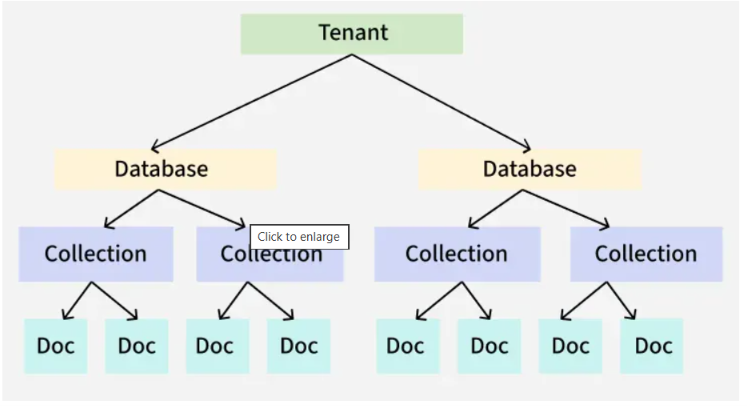

In [16]:
## intialize the neccessary libraries
import chromadb
import os
import uuid

In [22]:
## Now create the vector store
class VectorStore:
  """create the store and add the documents ,metadata,embeddings"""
  def __init__(self,persist_dir:str,collection_name:str):
    self.collection_name=collection_name
    self.persist_dir=persist_dir
    self.colletion=None ##Intially it is None
    self._load_the_store()

  def _load_the_store(self):
    os.makedirs(self.persist_dir,exist_ok=True)
    # create the client
    self.client=chromadb.PersistentClient(
      path=self.persist_dir
    )
    print("chromdb client has created")

    # create the collection
    self.collection=self.client.get_or_create_collection(
      name=self.collection_name,
      metadata={"description":"Pdf Documents Embeddings for RAG"}
    )
    print('Collection also created')

  def add_documents(self,documents:List[Any],embeddings:np.ndarray): 
    # we need to store ids,metadata,content,embeddings
    ids=[]
    all_metadata=[]
    all_documents=[]
    all_embeddings=[]

    for i,(doc,embedding) in enumerate(zip(documents,embeddings)):
      id=f"doc_{uuid.uuid4().hex[:8]}_{i}"
      ids.append(id)

      #prepare the metadata
      metadata=dict(doc.metadata) 
      metadata['doc_index']=i
      metadata['content_length']=len(doc.page_content)
      all_metadata.append(metadata)

      # prepare the page_content
      all_documents.append(doc.page_content)

      # prepare the embeddings
      all_embeddings.append(embedding.tolist())

    ## Add in collection
    self.collection.add(
      ids=ids,
      embeddings=all_embeddings,
      documents=all_documents,
      metadatas=all_metadata
    )
    print('successfully add the documents')


vector_store=VectorStore('../data/vectore_store','pdf_documents')
vector_store



chromdb client has created
Collection also created


In [23]:
## Now using the above two classes you generate the embeddings and store those in vectorDB

texts=[doc.page_content for doc in total_chunks]

## generate the emebedding
embeddings=embedding_manager.generate_embeddings(texts)

## store in db
vector_store.add_documents(total_chunks,embeddings)

The shape of the embeddings (27, 384)
successfully add the documents


### 5.Retreive Pipeline from vectorstore

In [36]:
# create RAG Retreiver
# It fetches data from vector store based on the user query

class RAGRetreiver:
  def __init__(self,vector_store:VectorStore,embedding_manager:EmbeddingManager):
    self.vector_store=vector_store
    self.embedding_mangager=embedding_manager

  def retreive(self,query:str,top_k:int=5,thresold_val:float=0.0)->List[dict[str,Any]]:
    # first convert the query into vector 
    input_embedding=embedding_manager.generate_embeddings([query])[0] ## it returns ndarray format
    results=vector_store.collection.query(
      query_embeddings=[input_embedding.tolist()],
      n_results=top_k
    )

    print('results',results)

    retreive_docs=[]
    if results['documents'] and results['documents'][0]:
      documents=results['documents'][0]
      metadatas=results['metadatas'][0]
      ids=results['ids'][0]
      distances=results['distances'][0]

    for i,(doc_id,metadata,doc,distance) in enumerate(zip(ids,metadatas,documents,distances)):
      ## Now convert the distance to cosine similarity
      similarity_score=1-distance
      if similarity_score>=thresold_val:
        retreive_docs.append({
          'id':doc_id,
          'metadata':metadata,
          'document':doc,
          'similarity':similarity_score,
          'rank':i+1
        })

    print(f"Retreived {len(retreive_docs)} docs after filtering") 
    return retreive_docs
rag_retreiver=RAGRetreiver(vector_store,embedding_manager)
rag_retreiver


In [37]:
## test with one user query to this pipeline
rag_retreiver.retreive('what are the AI projects')

The shape of the embeddings (1, 384)
results {'ids': [['doc_f3d3ef06_3', 'doc_78d41e2e_23', 'doc_54757efe_1', 'doc_a6235c27_2', 'doc_37908c82_22']], 'embeddings': None, 'documents': [['THE 2026 PORTFOLIO PROJECTS GUIDE\n3\nPROJECT 01\nAI Code Review & Repository Assistant\nBuild an AI tool that understands a codebase—not just a chatbot that answers prompts.\nThe problem\nDevelopers spend time understanding unfamiliar repositories, reviewing pull requests, finding risky changes, and writing\ntests. Build a repository assistant that helps with those workflows while keeping a human developer in control.\nCore features to build\n \x7f Connect a GitHub repository and index relevant source files.\n \x7f Summarize a repository, explain selected modules, and answer questions grounded in the codebase.\n \x7f Review pull requests and flag possible bugs, risky changes, missing tests, or security concerns.\n \x7f Suggest test cases and code improvements; require developer approval before any write

[{'id': 'doc_f3d3ef06_3',
  'metadata': {'content_length': 959,
   'keywords': '',
   'doc_index': 3,
   'page_label': '3',
   'author': 'OpenAI',
   'creator': '(unspecified)',
   'moddate': '2026-10-18T17:15:21+00:00',
   'producer': 'ReportLab PDF Library - (opensource)',
   'total_pages': 9,
   'title': 'The 2026 Portfolio Projects Guide',
   'file_type': 'pdf',
   'creationdate': '2026-10-18T17:15:21+00:00',
   'page': 2,
   'trapped': '/False',
   'subject': '(unspecified)',
   'source': '..\\data\\pdf_files\\2026_Portfolio_Projects_Guide (1).pdf',
   'source_file': '2026_Portfolio_Projects_Guide (1).pdf'},
  'document': 'THE 2026 PORTFOLIO PROJECTS GUIDE\n3\nPROJECT 01\nAI Code Review & Repository Assistant\nBuild an AI tool that understands a codebase—not just a chatbot that answers prompts.\nThe problem\nDevelopers spend time understanding unfamiliar repositories, reviewing pull requests, finding risky changes, and writing\ntests. Build a repository assistant that helps with t

#### 6.Augmentation


In [49]:
from dotenv import load_dotenv
load_dotenv()
from langchain.chat_models import init_chat_model
llm=init_chat_model(
  'google_genai:gemini-3.5-flash-lite'
)

def rag_simple(query,rag_retreiver,llm,top_k):

  results=rag_retreiver.retreive(query,top_k)

  context='/n/n'.join([doc['document'] for doc in results]) if results else ""
  if not context:
    return "No relevent context"

  # design the prompt
  prompt=f"""
  context:{context}
  based on this context ,tell me the answer consisely
  Answer: 
  """

  ## invoke the llm
  response=llm.invoke(prompt)
  return response

result=rag_simple("what are the ai projects that are good and the role is Ai engineer",rag_retreiver,llm,3)
print('result',result)




The shape of the embeddings (1, 384)
results {'ids': [['doc_a6235c27_2', 'doc_54757efe_1', 'doc_78d41e2e_23']], 'embeddings': None, 'documents': [['Quick selection guide\nIf you are targeting…\nStart with…\nWhy\nAI / Applied AI Engineer\nAI Code Review; Multi-Agent Planner\nRAG, tools, evaluation, integrations\nBackend Engineer\nEvent-Driven E-Commerce; Finance Platform\nAPIs, data, reliability, async workflows\nFull-Stack Engineer\nCollaborative Workspace; Finance Platform\nFrontend + backend + deployment\nDSA / Core CS strength\nRubik’s Cube Solver\nSearch, complexity, optimization', 'THE 2026 PORTFOLIO PROJECTS GUIDE\n2\nHow to use this guide\nThese are project blueprints, not rigid prescriptions. Choose one project aligned with your target role, build a small working\nversion first, and then add depth. You do not need to use every technology listed.\nWhat makes a portfolio project stronger?\nSolve a real problem. Explain who the user is, what pain point exists, and why the solution